# Étapes 5 et 6 (axe 2D) : agent SAC pour atterrir sur la voiture

Même démarche que `03_train_sac.ipynb` :
1. entraîner SAC dans l'environnement `LandingEnv` ([src/env_2d.py](../../src/env_2d.py)), où le drone est simulé par le LSTM 2D ;
2. regarder un atterrissage simulé ;
3. exporter la politique vers MATLAB, puis la tester sur le vrai drone (`landing/eval_landing.m`).

**Commande hybride** :
- **horizontal (RL)** : l'agent choisit la consigne d'inclinaison $\theta_{cmd} \in [-0{,}25 ; 0{,}25]$ rad (variation limitée à 0,02 rad par pas). Le stabilisateur d'attitude (PD) fait partie du drone ;
- **vertical (classique)** : une loi d'altitude (`descent_law`, PID) donne $U_{common}$ : le drone vole à 0,5 m, puis descend à 0,3 m/s dès qu'il est aligné avec la voiture depuis 0,5 s (|écart| < 10 cm et |écart de vitesse| < 0,15 m/s). S'il s'écarte de plus de 25 cm, il remonte.

Pourquoi : avec les deux commandes, l'agent apprenait bien à suivre la voiture mais refusait de descendre (pendant l'exploration, presque tous ses contacts étaient ratés, il en concluait que voler bas est risqué). Le RL se charge de la partie difficile (rattraper la voiture et rester exactement au-dessus pendant la descente), une règle simple se charge de la descente.

**Scénario** : la voiture roule déjà à vitesse constante. Le drone part à l'arrêt, 0,5 m au-dessus de la plateforme et derrière la voiture : il doit la rattraper, se placer au-dessus, puis se poser. Épisode de 15 s maximum. À l'entraînement, la vitesse de la voiture (0,5 à 1,5 m/s) et son avance (0,5 à 1 m) sont tirées au hasard à chaque vol ; sans randomisation : 1 m/s et 0,75 m.

**Atterrissage réussi** (au contact, $z \le 0$) : $|x - x_{car}| < 0{,}10$ m, $|v_z| < 0{,}3$ m/s, $|v_x - v_{car}| < 0{,}2$ m/s.

### Observation (10 valeurs)

$[\,x_{car} - x,\; z,\; v_{car} - v_x,\; v_z,\; 5\theta,\; \dot\theta,\; U_{common,prev},\; 4\,\theta_{cmd,prev},\; I_x,\; \min(t, 5)/5\,]$

- $\dot\theta$ est estimée par différence finie, comme dans MATLAB ;
- $I_x$ est l'intégrale de l'erreur en $x$ (bornée à ±1), comme $I$ en 1D ;
- les facteurs 5 et 4 mettent toutes les valeurs à peu près à la même échelle.

### Récompense (à chaque pas)

$$r = \underbrace{0{,}5\,e^{-(e_x/0{,}5)^2}}_{\text{aller vers la voiture}} + \underbrace{e^{-(e_x/0{,}15)^2}}_{\text{rester au-dessus}} - 0{,}05\min(e_v^2, 4) - 0{,}5\,\theta^2 - 5\,\Delta\theta_{cmd}^2$$

- **au contact** : $100\,q - 20\,(1 - q)$, avec $q = e^{-(e_x/0{,}1)^2}\,e^{-(v_z/0{,}3)^2}\,e^{-(e_v/0{,}2)^2} \in [0, 1]$ la qualité du contact (+100 si parfait, −20 si loin de la voiture) ;
- **si l'atterrissage est réussi** (les 3 critères) : en plus $1{,}5\,(N - k)$, tout ce que l'agent aurait encore pu gagner en restant en vol, pour qu'atterrir soit toujours le meilleur choix ;
- **drone perdu** : −50 et fin de l'épisode.

**Randomisation** (comme en 1D) : biais constants par vol sur $a_x$ (±0,5 m/s²), $a_z$ (±1 m/s²) et $\theta$ (±0,03 rad), plus du bruit.

In [1]:
import sys; sys.path.append("../..")
import numpy as np, matplotlib.pyplot as plt
from stable_baselines3 import SAC
from src.env_2d import LandingEnv, TS, N_STEPS

env = LandingEnv(model_path="../../models/lstm_2d.ckpt", scaler_path="../../models/lstm_2d_scaler.json")

agent = SAC("MlpPolicy", env, policy_kwargs=dict(net_arch=[64, 64]), seed=0,
            verbose=1, tensorboard_log="../../results/tensorboard")
agent.learn(total_timesteps=600_000)
agent.save("../../models/sac_landing")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ../../results/tensorboard/SAC_10
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 83       |
|    ep_rew_mean     | -49.3    |
| time/              |          |
|    episodes        | 4        |
|    fps             | 909      |
|    time_elapsed    | 0        |
|    total_timesteps | 332      |
| train/             |          |
|    actor_loss      | -0.593   |
|    critic_loss     | 18.5     |
|    ent_coef        | 0.933    |
|    ent_coef_loss   | -0.116   |
|    learning_rate   | 0.0003   |
|    n_updates       | 231      |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 67.2     |
|    ep_rew_mean     | -50.9    |
| time/              |          |
|    episodes        | 8        |
|    fps             | 815      |
|    time_elapsed    | 0        |
|    total_t

## Un atterrissage simulé (avec randomisation)

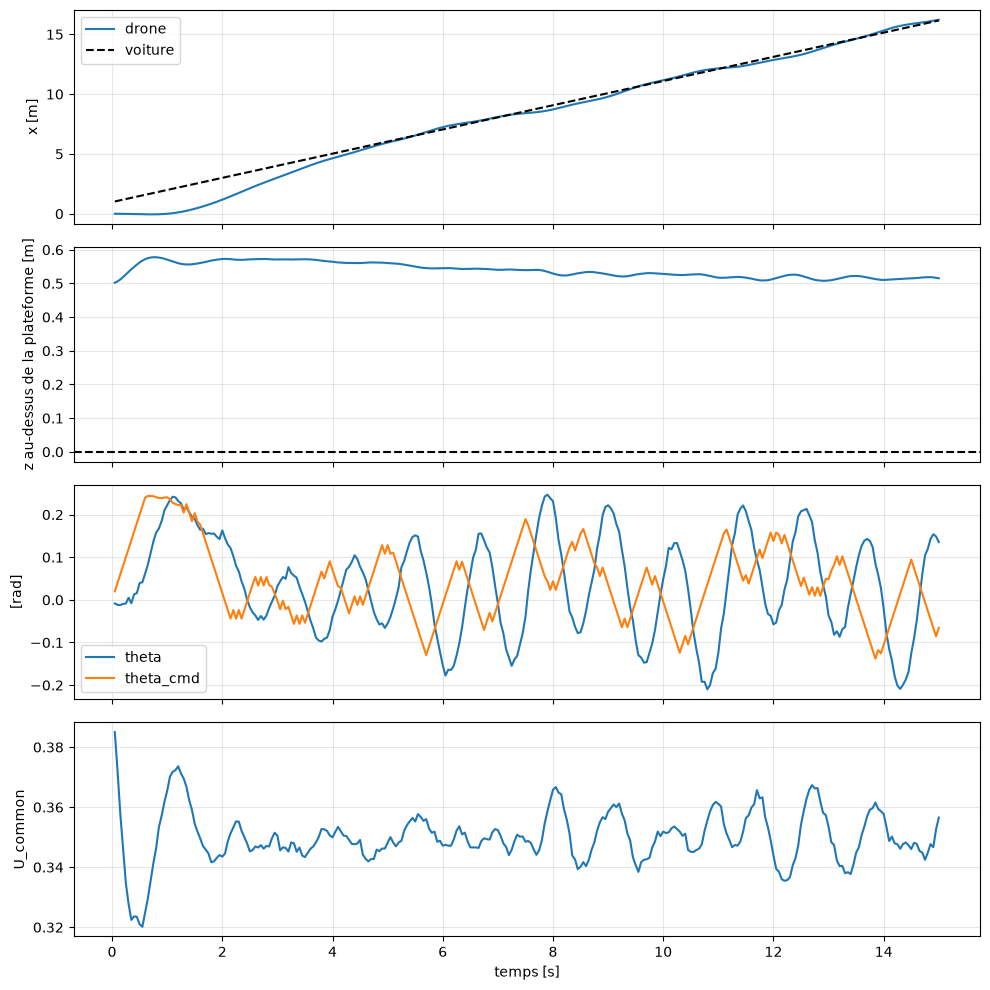

atterri : False  réussi : False  à t = 15.00 s
x - x_car = +0.066 m   vz = -0.02 m/s   vx - v_car = -0.14 m/s


In [2]:
def fly(env, agent, seed):
    obs, info = env.reset(seed=seed)
    log = []
    for _ in range(N_STEPS):
        action, _ = agent.predict(obs, deterministic=True)
        obs, r, term, trunc, info = env.step(action)
        log.append({**info["m"], "uc": info["m"]["uc_prev"], "tc": info["m"]["tc_prev"]})
        if term or trunc:
            break
    return log

log = fly(env, agent, seed=1)
g = lambda k: np.array([m[k] for m in log])
t = g("t")
fig, ax = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
ax[0].plot(t, g("x"), label="drone"); ax[0].plot(t, g("x_car"), "k--", label="voiture"); ax[0].set_ylabel("x [m]")
ax[1].plot(t, g("z")); ax[1].axhline(0, color="k", ls="--"); ax[1].set_ylabel("z au-dessus de la plateforme [m]")
ax[2].plot(t, g("theta"), label="theta"); ax[2].plot(t, g("tc"), label="theta_cmd"); ax[2].set_ylabel("[rad]")
ax[3].plot(t, g("uc")); ax[3].set_ylabel("U_common"); ax[3].set_xlabel("temps [s]")
for a in ax: a.grid(alpha=0.3)
ax[0].legend(); ax[2].legend(); plt.tight_layout(); plt.show()

m = log[-1]
print(f"atterri : {m['landed']}  réussi : {m['success']}  à t = {m['t']:.2f} s")
print(f"x - x_car = {m['x'] - m['x_car']:+.3f} m   vz = {m['vz']:+.2f} m/s   vx - v_car = {m['vx'] - m['v_car']:+.2f} m/s")

## Taux de réussite sur 50 vols randomisés

In [3]:
ok = [fly(env, agent, seed=100 + s)[-1]["success"] for s in range(50)]
print(f"atterrissages réussis : {sum(ok)} / 50")

atterrissages réussis : 11 / 50


## Export vers MATLAB

On écrit les poids de la politique dans `landing/policy_2d.mat` avec la même fonction que pour le 1D (`export_policy.py`).
**Ensuite, dans MATLAB :** lancer `landing/eval_landing.m`. La politique vole sur `uav_plant.m` (le vrai drone, 4 moteurs, bruit de capteur) avec la même loi d'altitude, et elle est comparée à un PD sur $x$ à la place de la politique.

In [4]:
sys.path.append("../../rl_interface")
from export_policy import _policy_matrices
from scipy.io import savemat

savemat("../../landing/policy_2d.mat", _policy_matrices(agent))
print("landing/policy_2d.mat écrit : lancer landing/eval_landing.m dans MATLAB")

landing/policy_2d.mat écrit : lancer landing/eval_landing.m dans MATLAB
